# Lab 2 · Customer churn, end to end: from raw data to a call list

**AI Foundations · Practical Lab 2 (revises Lessons 1–7)**

<a href="https://colab.research.google.com/github/MusaBangash/Python-Variables/blob/main/ml/labs/lab2_customer_churn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 1 predicted a **number**. This lab predicts a **yes/no** (will the customer leave?) and goes all the way to what a company actually needs: **a list of customers to call tomorrow, with a reason for each call, and the expected profit.**

| Step | What | Revises |
|---|---|---|
| 1 | The business problem, in money | 1, 3 |
| 2 | Load, clean, and a hidden data problem | 1, 2 |
| 3 | Stratified split | 2 |
| 4 | Explore: who leaves? | 1, 5 |
| 5 | Baselines and the accuracy trap | 3 |
| 6 | Logistic regression in a pipeline | 4 |
| 7 | Confusion matrix, precision, recall, ROC and PR curves | 3 |
| 8 | Choose the threshold by **profit**, not by 0.5 | 3 |
| 9 | Calibration: can we trust the probabilities? | 3 |
| 10 | Trees, forests and boosting: a fair contest | 5, 6 |
| 11 | Pick the winner, test once | 2 |
| 12 | Why does the model flag customers? | 4, 5 |
| 13 | Segments for the campaign (k-means) | 7 |
| 14 | Production: save, score, call list, monitoring | — |
| 15 | Summary and exercises | all |

## Step 1 · The business problem, in money

A telecom company loses about **1 in 4** customers. The retention team can call customers and offer a discount. Our numbers (set with the business team; change them and re-run!):

| Item | Value |
|---|---|
| Cost of one call + offer | **\$100** |
| Chance a customer who **was** going to leave stays because of the offer | **30%** |
| Value of keeping a customer (future profit) | **\$1,500** |

So calling a real leaver earns on average 0.30 × \$1,500 − \$100 = **+\$350**. Calling a customer who was staying anyway: **−\$100** (wasted offer).

**Our job:** give every customer a **probability of leaving**, then decide **whom to call** to make the most money.

- Answer is yes/no → **classification** (supervised).
- We need good **ranking** (call the riskiest first) **and** trustworthy **probabilities** (to compute expected profit).

> 📘 **Revision (Lesson 3):** accuracy is not the goal; the cost of each kind of mistake is.

## Step 2 · Load and clean

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (9, 5); plt.rcParams['font.size'] = 12

url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/telco-churn.csv'
if not os.path.exists('telco-churn.csv'):
    urlretrieve(url, 'telco-churn.csv')

df = pd.read_csv('telco-churn.csv')
print(df.shape)
df.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Something is wrong:** `TotalCharges` (money!) is stored as **text**, not a number. That usually means some cells contain something that isn't a number. Let's find them instead of blindly converting.

In [3]:
not_numeric = pd.to_numeric(df.TotalCharges, errors='coerce').isna()
print('Rows where TotalCharges is not a number:', not_numeric.sum())
df.loc[not_numeric, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Detective work:** all 11 rows are blank, and **every one has tenure = 0**. These are brand-new customers who haven't received a bill yet.

Options to fill them:
| Option | Problem |
|---|---|
| Delete the rows | throws away real customers (and new customers are exactly who we care about) |
| Fill with the average (~\$2,300) | **wrong**: a customer who hasn't paid anything would look like a two-year customer |
| **Fill with 0** | ✅ matches reality: they have paid \$0 so far |

**Lesson:** look at *why* data is missing before choosing how to fill it.

In [4]:
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce').fillna(0)
df['Churn'] = (df.Churn == 'Yes').astype(int)          # target as 0/1

print('Duplicate customer IDs:', df.customerID.duplicated().sum())
print('Rows identical apart from the ID:', df.drop(columns='customerID').duplicated().sum())

Duplicate customer IDs: 0
Rows identical apart from the ID: 22


**22 rows look identical apart from the ID.** Unlike Lab 1, these have **different customer IDs**: they are different people who happen to have the same simple profile (e.g. new customers with only phone service). So we **keep** them. Removing them would distort reality.

We also drop `customerID` from the features: it's a random label with no meaning, and a model could memorise it.

> 📘 **Revision (Lesson 2):** a duplicate *record* leaks; two different customers with the same profile don't.

## Step 3 · Stratified split

Only ~26.5% of customers churn. A random split could, by luck, put 24% in train and 30% in test. `stratify=` keeps the **same churn rate** in both.

In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df.Churn, random_state=42)
print(f'Train: {len(train_df)} customers, churn {train_df.Churn.mean():.1%}')
print(f'Test:  {len(test_df)} customers, churn {test_df.Churn.mean():.1%}   (locked until Step 11)')

target = 'Churn'
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_cols = [c for c in df.columns if c not in numeric_cols + ['customerID', target]]
X_train, y_train = train_df[numeric_cols + categorical_cols], train_df[target]
X_test,  y_test  = test_df[numeric_cols + categorical_cols],  test_df[target]
print(len(numeric_cols), 'numeric +', len(categorical_cols), 'categorical features')

Train: 5634 customers, churn 26.5%
Test:  1409 customers, churn 26.5%   (locked until Step 11)
4 numeric + 15 categorical features


## Step 4 · Explore: who leaves?

We look at churn **rate** per group: the share of customers in that group who left.

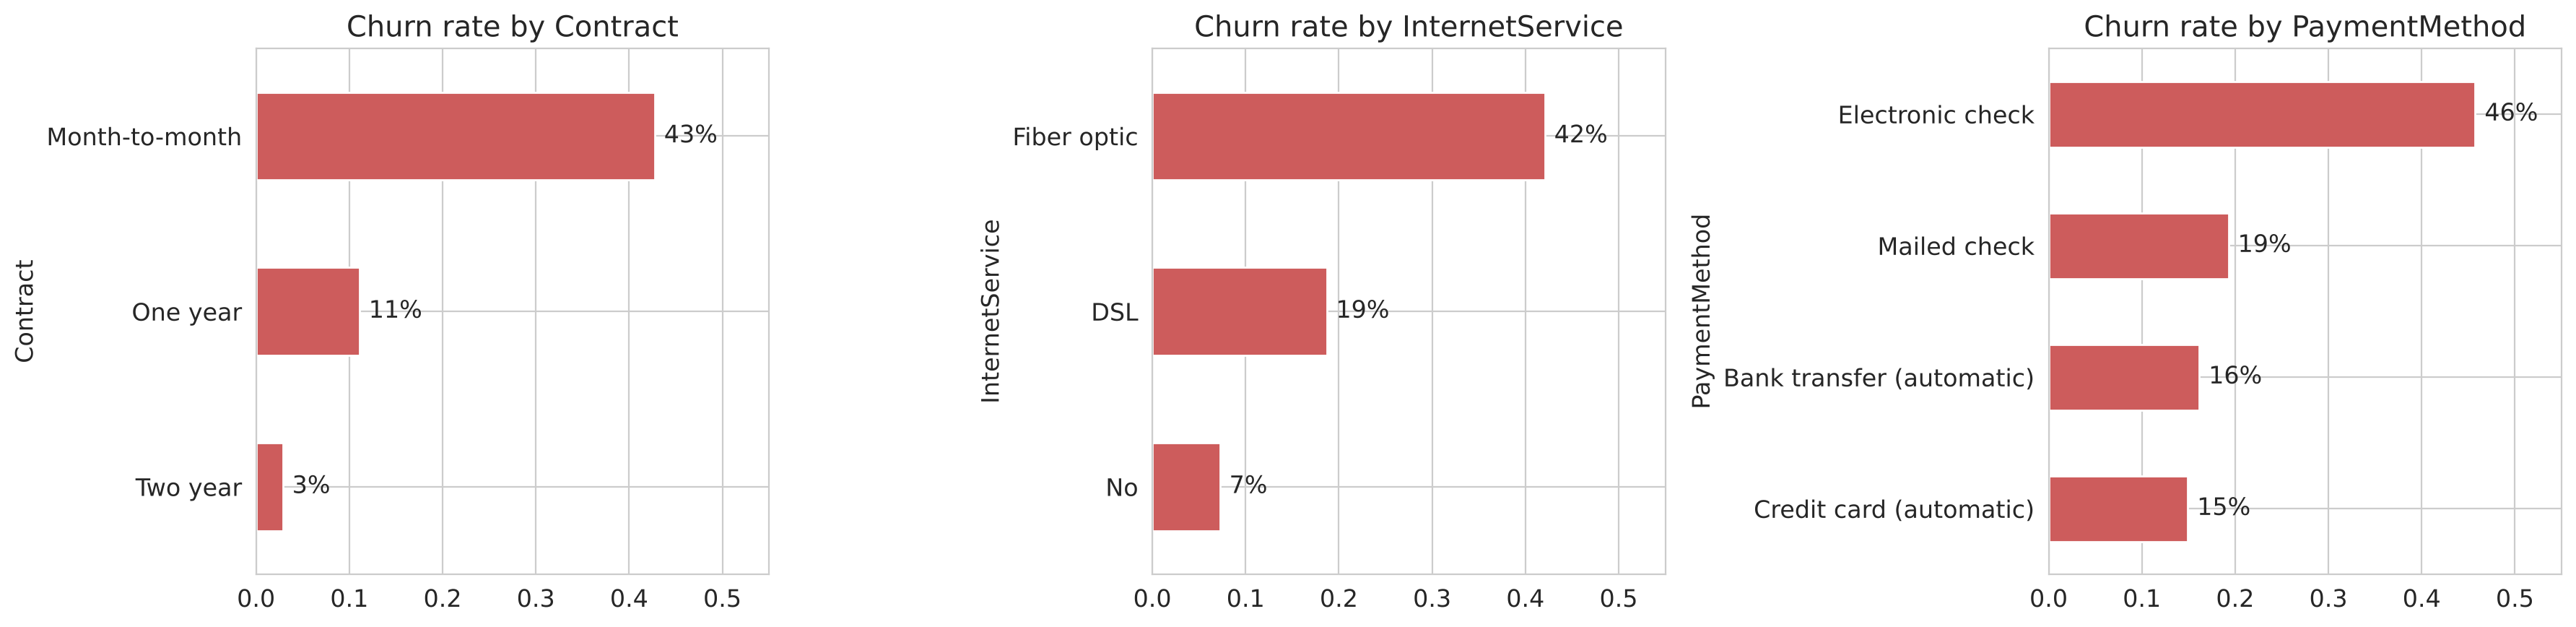

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    rate = train_df.groupby(col).Churn.mean().sort_values()
    rate.plot.barh(ax=ax, color='indianred'); ax.set_title(f'Churn rate by {col}'); ax.set_xlim(0, .55)
    for i, v in enumerate(rate): ax.text(v + .01, i, f'{v:.0%}', va='center')
plt.tight_layout(); plt.show()

- **Contract:** month-to-month 43% vs two-year **3%**. The single strongest signal (it was the root of our Lesson 5 tree).
- **Fiber internet:** 42%, double DSL. Possibly price or service problems: a question for the business.
- **Electronic check:** 46%; automatic payments ~15%. People who must actively pay every month leave more.

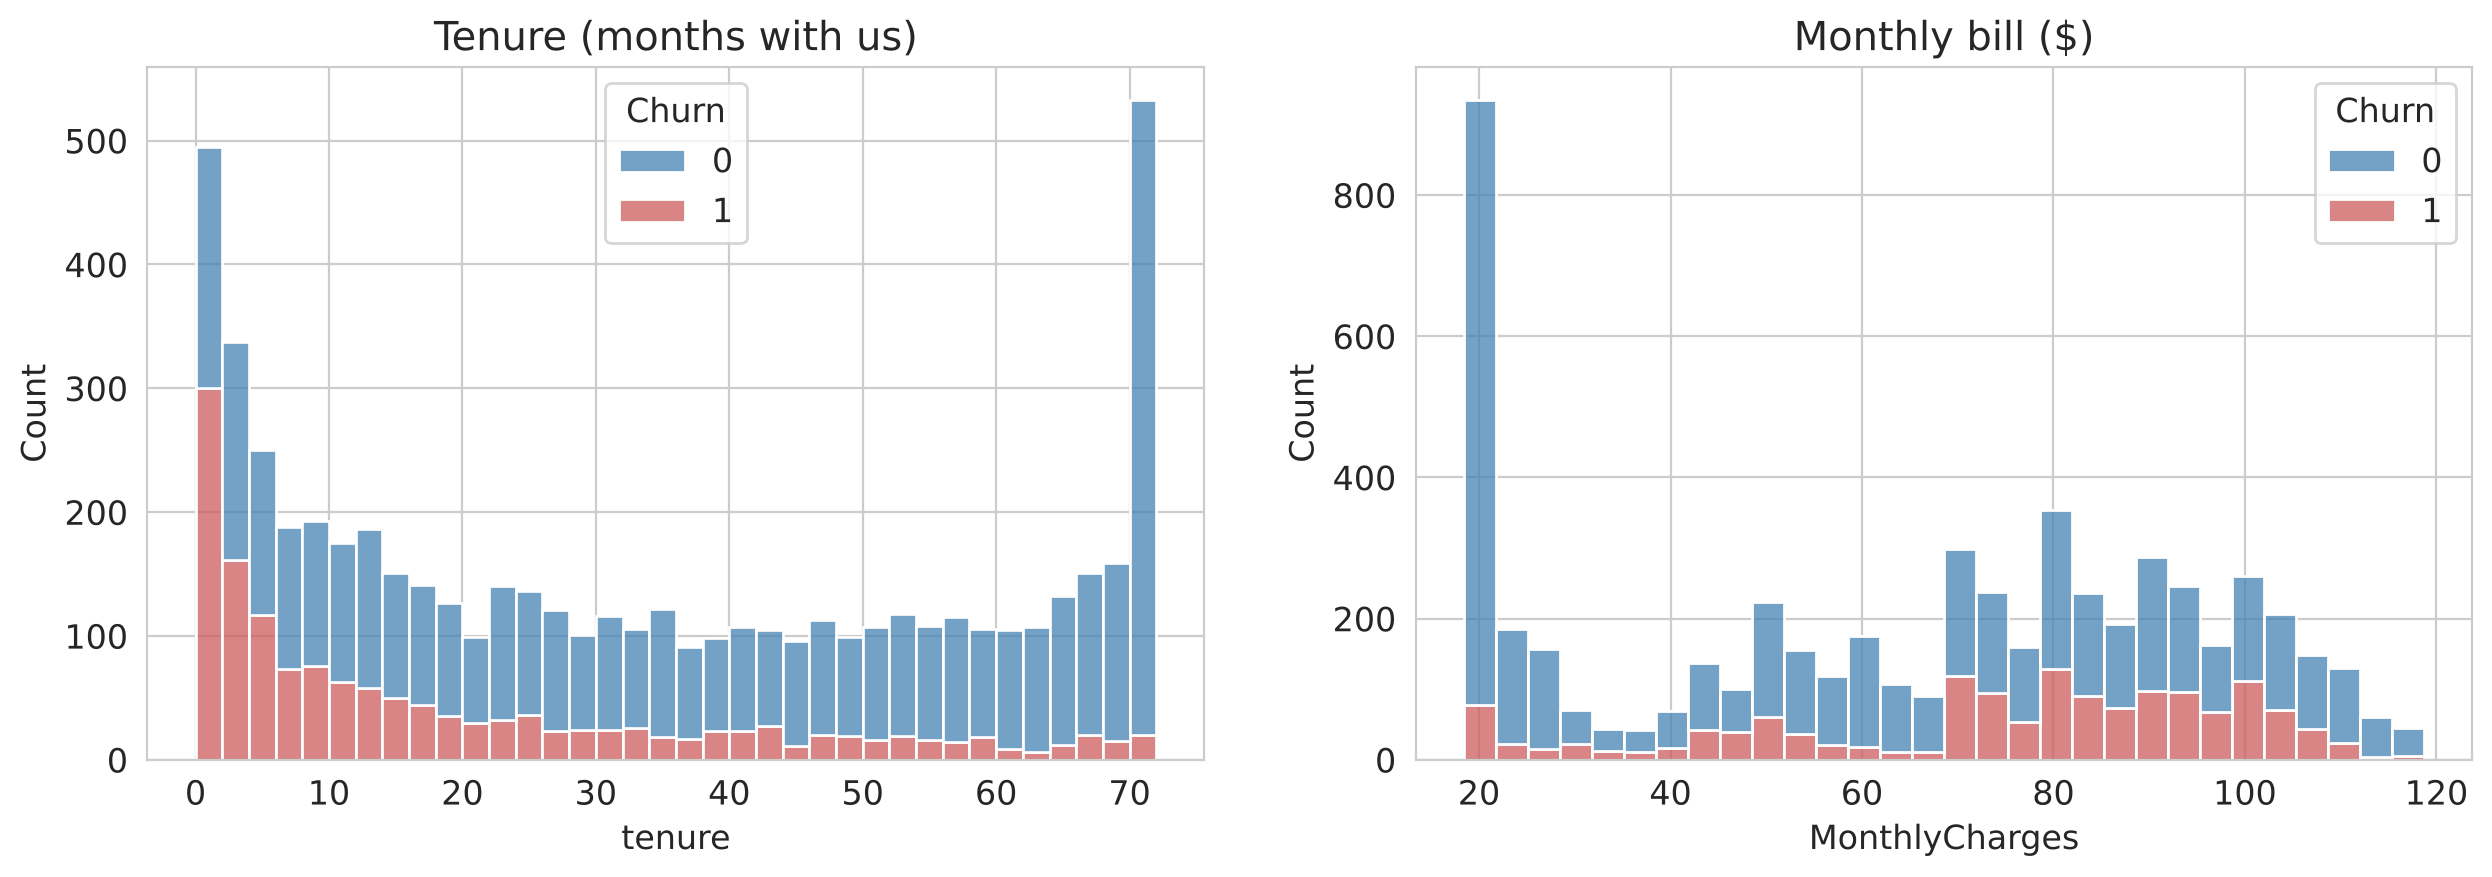

        tenure  MonthlyCharges
Churn                         
stayed    38.0           64.40
left      10.0           79.95


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=train_df, x='tenure', hue='Churn', bins=36, multiple='stack', ax=ax[0], palette={0: 'steelblue', 1: 'indianred'})
ax[0].set_title('Tenure (months with us)')
sns.histplot(data=train_df, x='MonthlyCharges', hue='Churn', bins=30, multiple='stack', ax=ax[1], palette={0: 'steelblue', 1: 'indianred'})
ax[1].set_title('Monthly bill ($)')
plt.show()
print(train_df.groupby('Churn')[['tenure', 'MonthlyCharges']].median().rename(index={0: 'stayed', 1: 'left'}))

Leavers are mostly **new** (median 10 months vs 38) and pay **more** per month. Risk is highest in the first year: a clear message for the business ("protect new customers").

## Step 5 · Baselines and the accuracy trap

The dumbest classifier says **"nobody leaves"** for everyone. Let's score it with several metrics, using 5-fold **stratified** cross-validation.

| Metric | Meaning | Good for |
|---|---|---|
| Accuracy | % correct | balanced classes only |
| **ROC AUC** | chance a random leaver gets a higher score than a random stayer (0.5 = random, 1 = perfect) | ranking quality |
| **Average precision (PR AUC)** | precision averaged over all recall levels; baseline = churn rate | rare positive class |
| **Log loss** | how good the probabilities are (lower = better) | probability quality |

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

def evaluate(name, model):
    cv = cross_validate(model, X_train, y_train, cv=folds,
                        scoring=('roc_auc', 'average_precision', 'accuracy', 'neg_log_loss'))
    results[name] = {'ROC AUC': cv['test_roc_auc'].mean(), 'AUC ±': cv['test_roc_auc'].std(),
                     'Avg precision': cv['test_average_precision'].mean(),
                     'Log loss': -cv['test_neg_log_loss'].mean(), 'Accuracy': cv['test_accuracy'].mean()}
    return pd.DataFrame(results).T.round(4)

evaluate('0 · Baseline: nobody leaves', DummyClassifier(strategy='most_frequent'))

,ROC AUC,AUC ±,Avg precision,Log loss,Accuracy
0 · Baseline: nobody leaves,0.5,0.0,0.2654,9.5643,0.7346


**73.5% accuracy for a model that does nothing!** It never finds a single leaver. ROC AUC 0.5 and average precision 0.265 (= the churn rate) expose it immediately. Its log loss is huge (9.6) because it is *certain* nobody leaves, and log loss punishes confident mistakes very hard.

> 📘 **Revision (Lesson 3):** with imbalanced classes, accuracy hides failure. Use AUC, precision/recall, and money.

## Step 6 · Logistic regression in a pipeline

Logistic regression = linear regression whose output is squeezed into a probability (0–1) by the **sigmoid** function. It's trained with **log loss** by gradient descent (Lesson 4).

Pipeline, same as Lab 1: **scale** numbers, **one-hot** encode categories (`handle_unknown='ignore'` so a new category value in production doesn't crash the system). `C` controls regularisation: small C = strong penalty.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

for C in [0.01, 0.1, 1.0]:
    table = evaluate(f'1 · Logistic regression C={C}', make_pipeline(preprocess, LogisticRegression(C=C, max_iter=2000)))
table

,ROC AUC,AUC ±,Avg precision,Log loss,Accuracy
0 · Baseline: nobody leaves,0.5000,0.0000,0.2654,9.5643,0.7346
1 · Logistic regression C=0.01,0.8435,0.0109,0.6576,0.4208,0.8048
1 · Logistic regression C=0.1,0.8455,0.0120,0.6607,0.4170,0.8012
1 · Logistic regression C=1.0,0.8462,0.0126,0.6617,0.4166,0.8021


**ROC AUC ≈ 0.846** from baseline 0.5. The value of C barely matters here: 45 encoded columns and 5,600 customers is not an overfitting situation (Lab 1, Step 9 again). We keep **C = 0.1**.

## Step 7 · What do the predictions look like? Confusion matrix and curves

To study errors honestly, we need predictions for training customers **made by a model that didn't train on them**. `cross_val_predict` does exactly that: each customer is predicted by the fold-model that left them out.

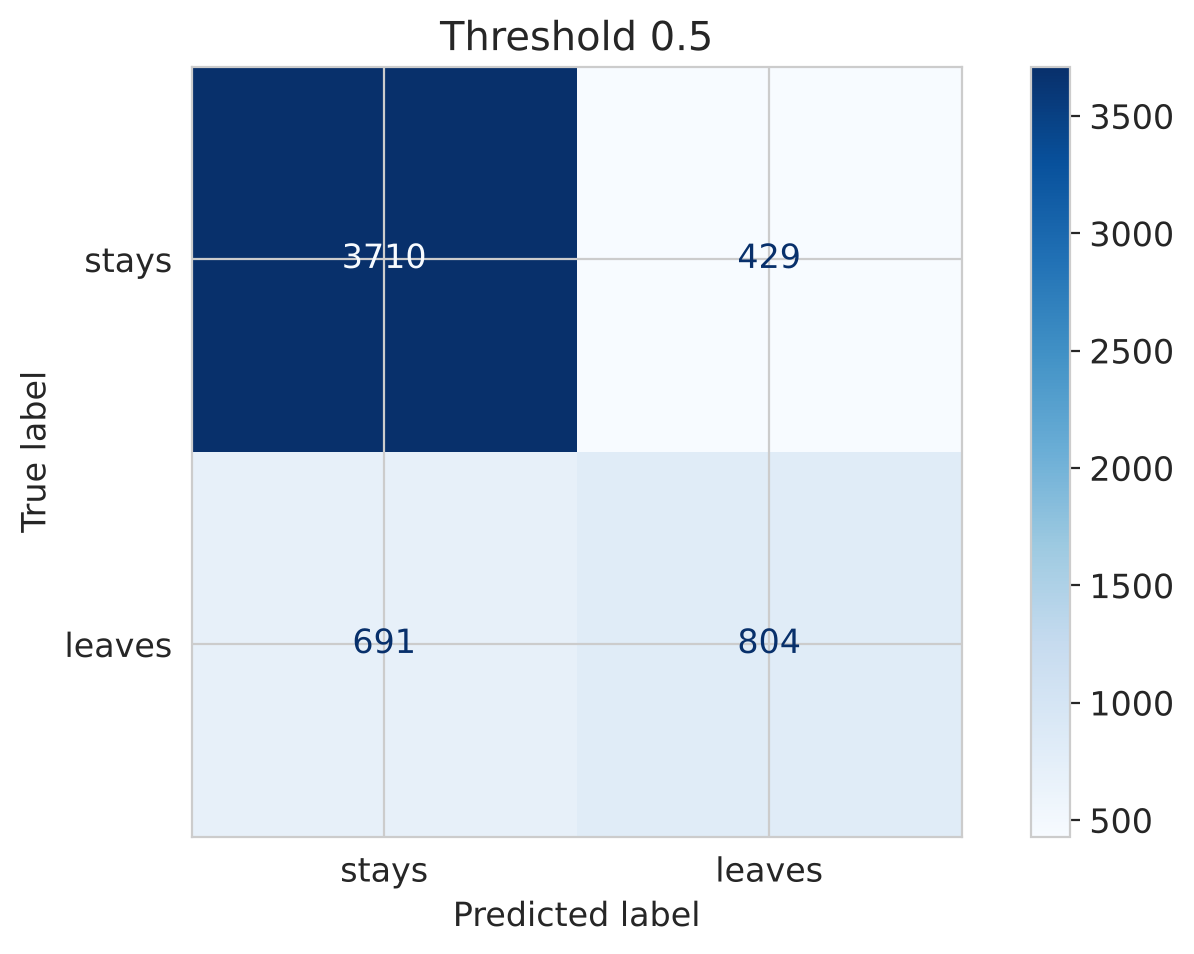

Precision: 65.2% of customers we flag really leave
Recall:    53.8% of all leavers are caught
F1:        0.589


In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score

logreg = make_pipeline(preprocess, LogisticRegression(C=0.1, max_iter=2000))
p_logreg = cross_val_predict(logreg, X_train, y_train, cv=folds, method='predict_proba')[:, 1]

flag = (p_logreg >= 0.5).astype(int)        # the default rule: call if probability >= 0.5
ConfusionMatrixDisplay(confusion_matrix(y_train, flag), display_labels=['stays', 'leaves']).plot(cmap='Blues', values_format='d')
plt.title('Threshold 0.5'); plt.show()
print(f'Precision: {precision_score(y_train, flag):.1%} of customers we flag really leave')
print(f'Recall:    {recall_score(y_train, flag):.1%} of all leavers are caught')
print(f'F1:        {f1_score(y_train, flag):.3f}')

At the default 0.5 threshold, we catch only **~54%** of leavers. **Is 0.5 the right threshold?** Nothing in our business says so. 0.5 is just a default. The curves show **every** possible threshold at once:

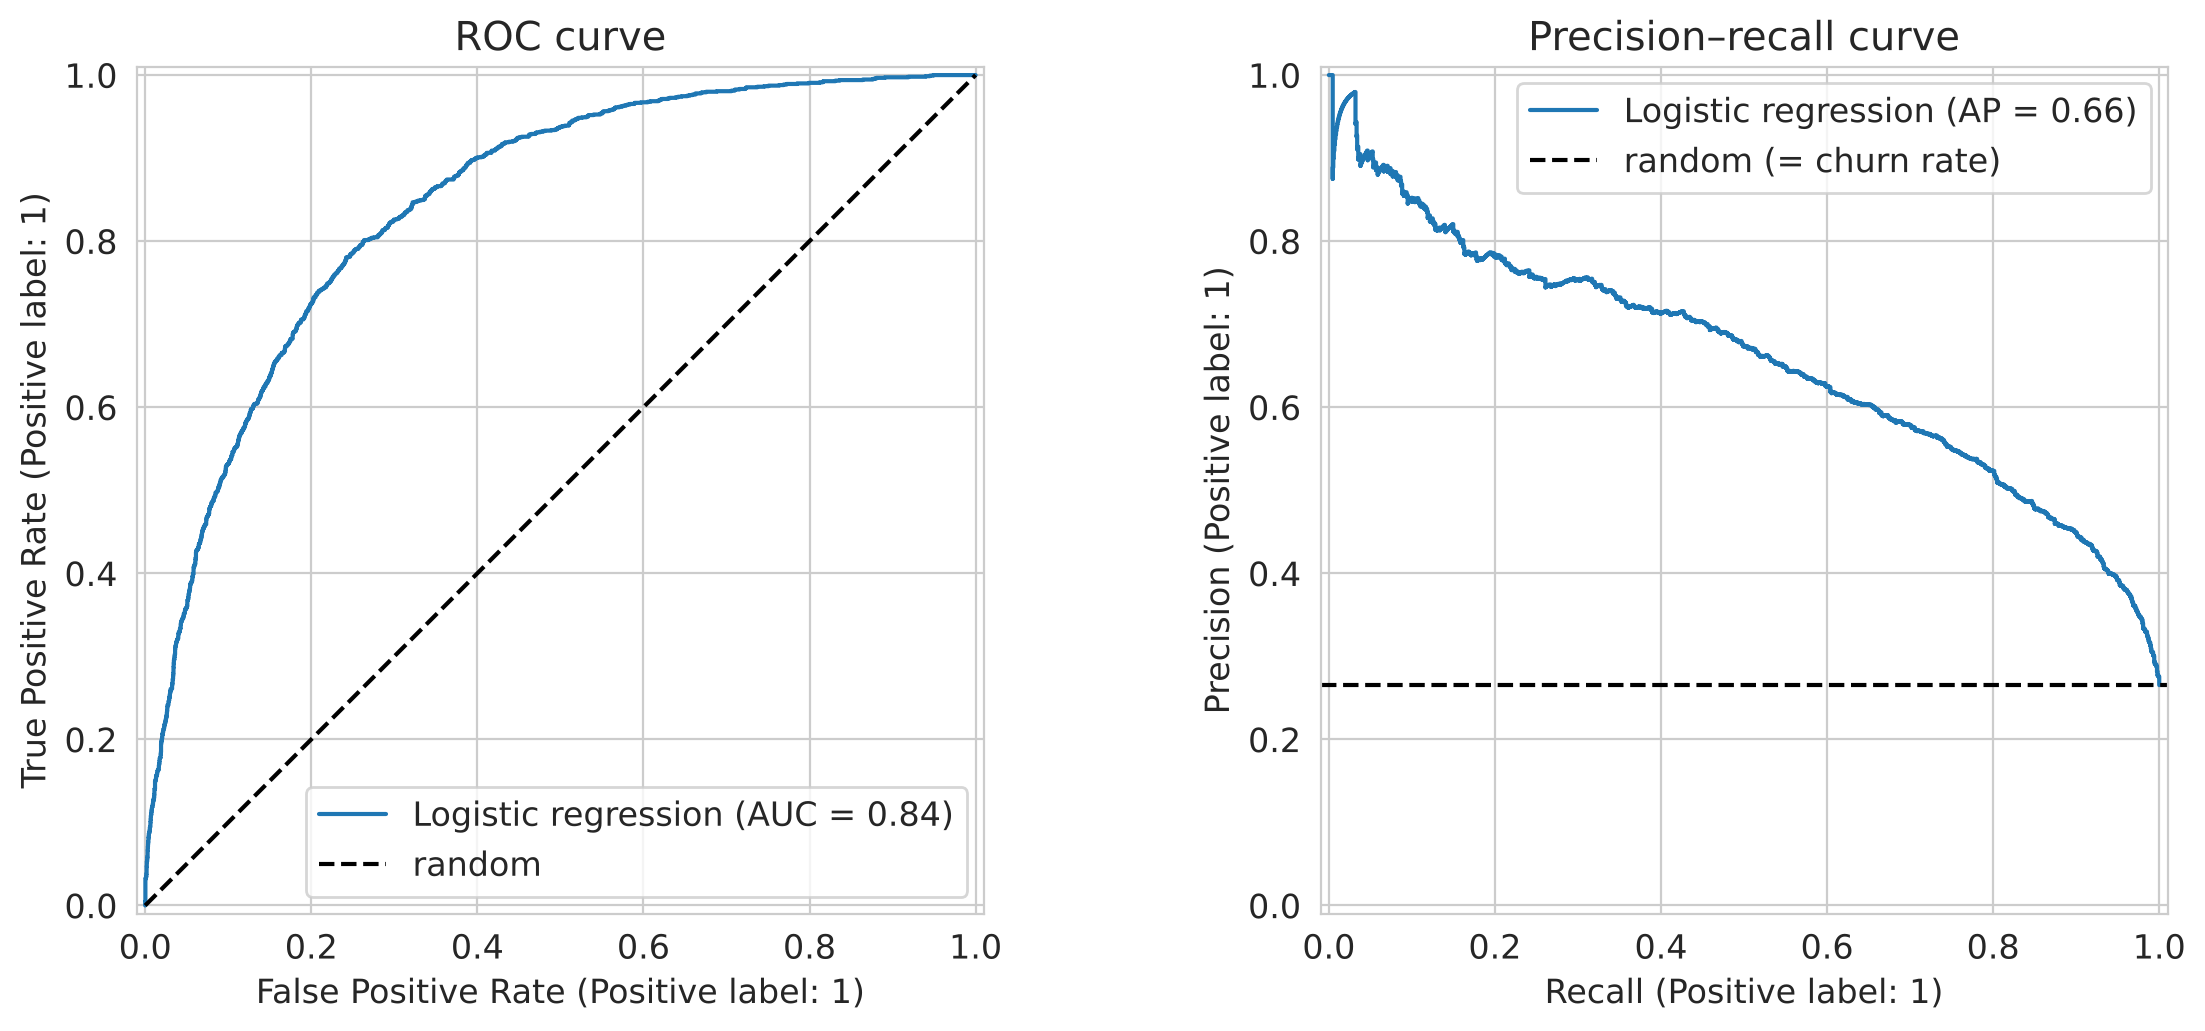

In [11]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
RocCurveDisplay.from_predictions(y_train, p_logreg, ax=ax[0], name='Logistic regression')
ax[0].plot([0, 1], [0, 1], 'k--', label='random'); ax[0].legend(); ax[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_train, p_logreg, ax=ax[1], name='Logistic regression')
ax[1].axhline(y_train.mean(), color='k', ls='--', label='random (= churn rate)'); ax[1].legend(); ax[1].set_title('Precision–recall curve')
plt.show()

- **ROC:** how well we rank leavers above stayers. Bowing toward the top-left = good.
- **Precision–recall:** the honest view for a rare class. As we flag more customers (recall ↑), the share of real leavers among them (precision) falls.

Moving the threshold = moving along these curves. **Where should we stand?** Ask the money.

## Step 8 · Choose the threshold by profit

For any threshold: profit = (real leavers called × 0.30 × \$1,500) − (everyone called × \$100). We compute it for every threshold on the **cross-validated** predictions (never on the test set: choosing the threshold is part of training).

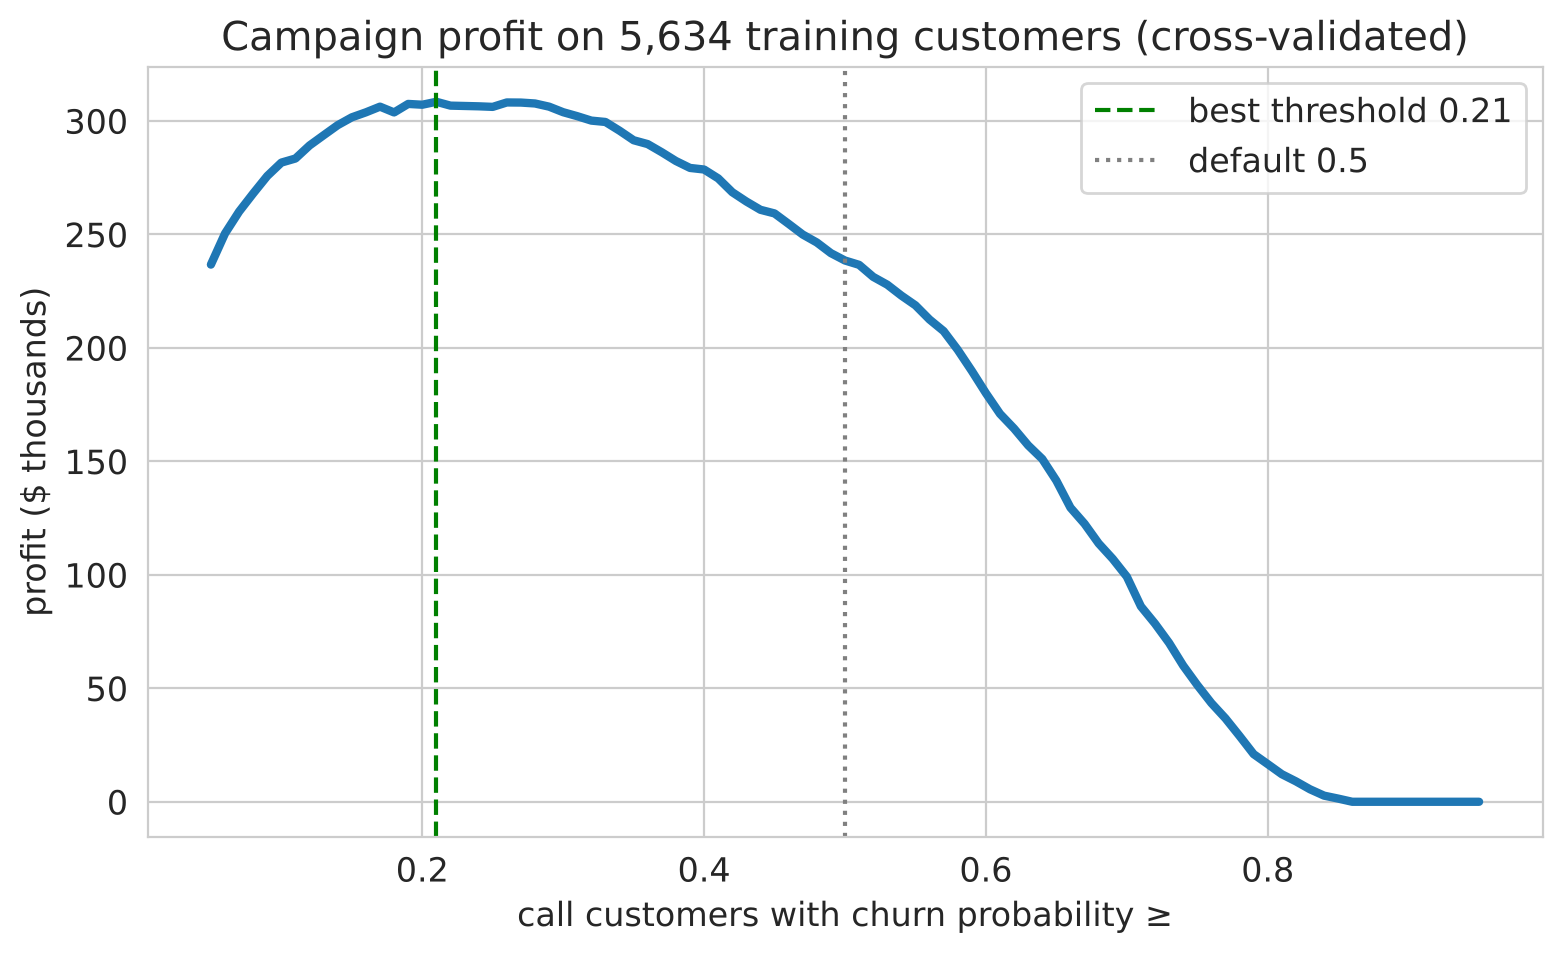

Best threshold: 0.21 → profit $308,450, calls 2,617
Default 0.50  → profit $238,500
Call everyone → profit $109,350


In [12]:
COST_PER_CALL = 100
SAVE_RATE = 0.30
CUSTOMER_VALUE = 1500

def campaign_profit(y_true, probs, threshold):
    called = probs >= threshold
    leavers_called = (called & (np.asarray(y_true) == 1)).sum()
    return leavers_called * SAVE_RATE * CUSTOMER_VALUE - called.sum() * COST_PER_CALL

thresholds = np.arange(0.05, 0.96, 0.01)
profits = [campaign_profit(y_train, p_logreg, t) for t in thresholds]
best_t = thresholds[int(np.argmax(profits))]

plt.plot(thresholds, np.array(profits) / 1000, lw=3)
plt.axvline(best_t, color='green', ls='--', label=f'best threshold {best_t:.2f}')
plt.axvline(0.5, color='grey', ls=':', label='default 0.5')
plt.xlabel('call customers with churn probability ≥'); plt.ylabel('profit ($ thousands)'); plt.legend()
plt.title('Campaign profit on 5,634 training customers (cross-validated)'); plt.show()

print(f'Best threshold: {best_t:.2f} → profit ${max(profits):,.0f}, calls {np.sum(p_logreg >= best_t):,}')
print(f'Default 0.50  → profit ${campaign_profit(y_train, p_logreg, 0.5):,.0f}')
print(f'Call everyone → profit ${campaign_profit(y_train, p_logreg, 0):,.0f}')

**The best threshold is far below 0.5** (around 0.2), and it earns about **30% more** than the default.

**Why so low?** Missing a leaver costs us \$350 of expected value; a wasted call costs only \$100. When misses are expensive, we should call more people.

### The shortcut formula
Call a customer when expected gain > cost: p × 0.30 × \$1,500 > \$100 → **p > 100 / 450 ≈ 0.22**. That's almost exactly what the search found. But this formula only works if the probabilities are **honest**. That's the next step.

> 📘 **Revision (Lesson 3):** the threshold is a **business decision**; the model only provides the ranking and the probabilities.

## Step 9 · Calibration: can we trust the probabilities?

A model is **calibrated** if, among customers it gives 30%, about 30% really leave. Let's check, and compare with a popular "fix" for imbalance: `class_weight='balanced'`, which makes the model pay more attention to leavers.

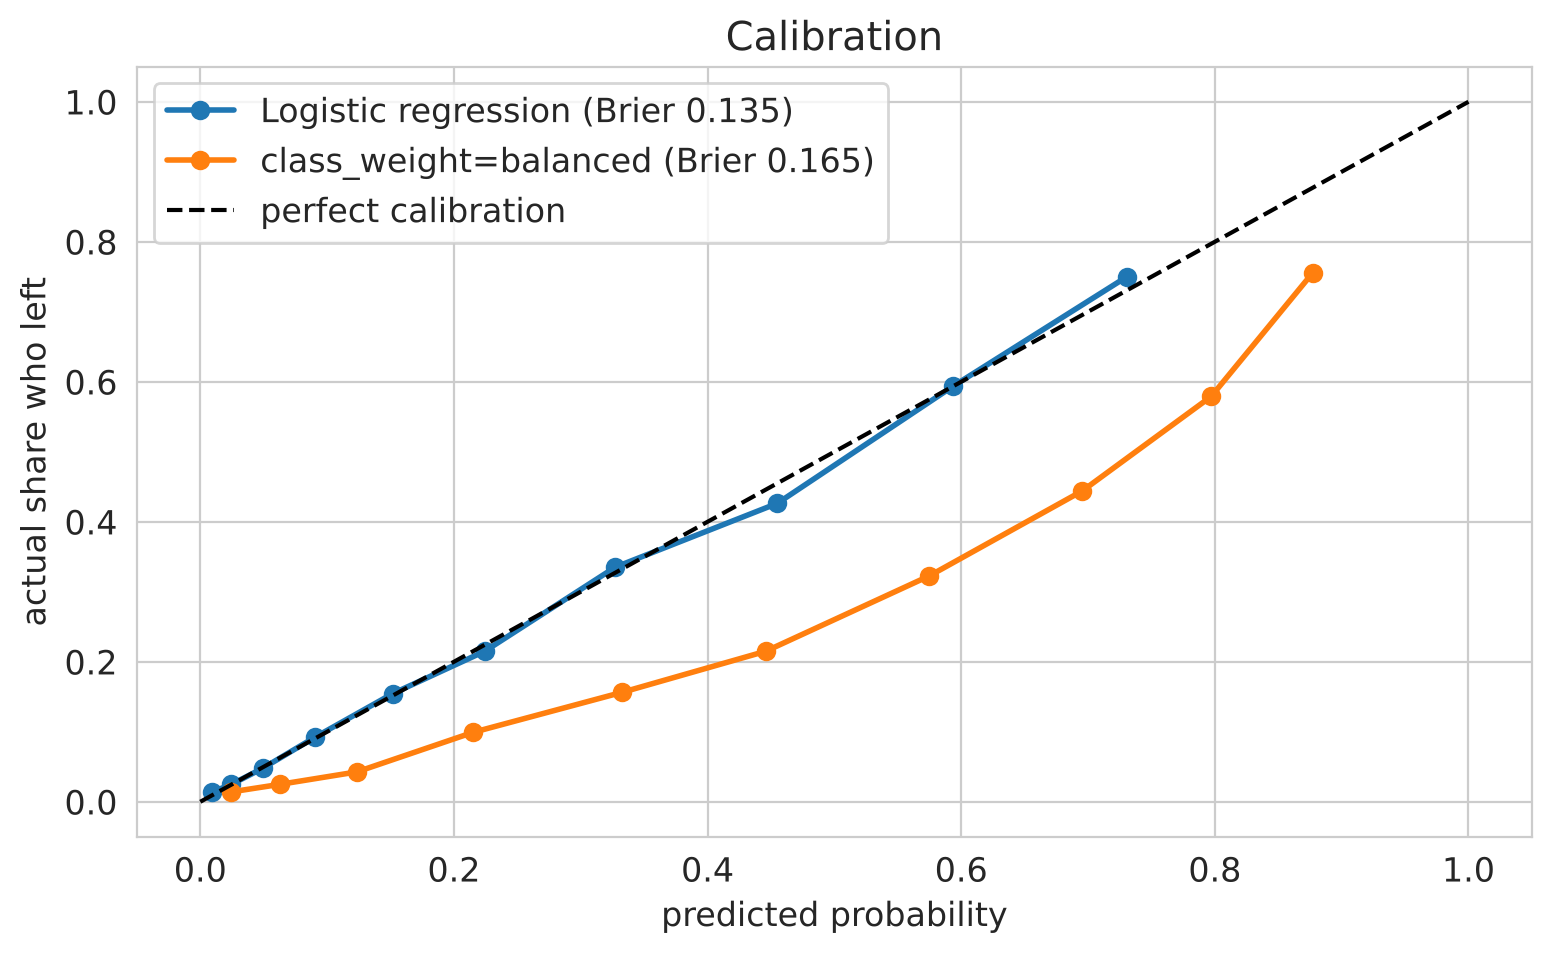

Average predicted probability: plain 0.266, balanced 0.415; real churn rate 0.265


In [13]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

p_balanced = cross_val_predict(make_pipeline(preprocess, LogisticRegression(C=0.1, max_iter=2000, class_weight='balanced')),
                               X_train, y_train, cv=folds, method='predict_proba')[:, 1]

for name, probs in [('Logistic regression', p_logreg), ('class_weight=balanced', p_balanced)]:
    frac, mean_pred = calibration_curve(y_train, probs, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac, 'o-', lw=2, label=f'{name} (Brier {brier_score_loss(y_train, probs):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='perfect calibration')
plt.xlabel('predicted probability'); plt.ylabel('actual share who left'); plt.legend(); plt.title('Calibration'); plt.show()

print(f'Average predicted probability: plain {p_logreg.mean():.3f}, balanced {p_balanced.mean():.3f}; real churn rate {y_train.mean():.3f}')

- **Plain logistic regression** sits on the diagonal: its probabilities are honest.
- **Balanced** predicts ~41% on average when the truth is 26.5%. When it says 0.70, only ~44% actually leave. Plug those numbers into the profit formula and you would waste money.

**Lesson:** `class_weight='balanced'` can help ranking for some models, but it **breaks probabilities**. With honest probabilities, handle imbalance with the **threshold** (Step 8), not by re-weighting. (If you must re-weight, re-calibrate afterwards with `CalibratedClassifierCV`.)

## Step 10 · Trees, forests and boosting: a fair contest

Same folds, same metrics, for every model. Trees don't need scaling, so they get a simpler preprocessing step.

In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

preprocess_tree = ColumnTransformer([
    ('num', 'passthrough', numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

# tune the single tree's size with cross-validation (Lesson 5)
search = GridSearchCV(make_pipeline(preprocess_tree, DecisionTreeClassifier(random_state=0)),
                      {'decisiontreeclassifier__max_depth': [3, 5, 8],
                       'decisiontreeclassifier__min_samples_leaf': [20, 50, 100]},
                      cv=folds, scoring='roc_auc').fit(X_train, y_train)
print('Best tree settings:', search.best_params_)
evaluate('2 · Decision tree (tuned)', search.best_estimator_)

evaluate('3 · Random forest', make_pipeline(preprocess_tree, RandomForestClassifier(n_estimators=500, min_samples_leaf=10, random_state=0, n_jobs=-1)))
evaluate('4 · Gradient boosting (defaults)', make_pipeline(preprocess_tree, HistGradientBoostingClassifier(random_state=0)))
boosting = make_pipeline(preprocess_tree, HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                                       min_samples_leaf=40, early_stopping=True, random_state=0))
table = evaluate('5 · Gradient boosting (tuned)', boosting)
table.sort_values('ROC AUC', ascending=False)

Best tree settings: {'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 100}


,ROC AUC,AUC ±,Avg precision,Log loss,Accuracy
5 · Gradient boosting (tuned),0.8492,0.0120,0.6677,0.4125,0.8042
3 · Random forest,0.8469,0.0088,0.6619,0.4157,0.8025
1 · Logistic regression C=1.0,0.8462,0.0126,0.6617,0.4166,0.8021
1 · Logistic regression C=0.1,0.8455,0.0120,0.6607,0.4170,0.8012
1 · Logistic regression C=0.01,0.8435,0.0109,0.6576,0.4208,0.8048
4 · Gradient boosting (defaults),0.8364,0.0054,0.6471,0.4356,0.7954
2 · Decision tree (tuned),0.8329,0.0108,0.6268,0.4902,0.7934
0 · Baseline: nobody leaves,0.5000,0.0000,0.2654,9.5643,0.7346


**Reading the leaderboard:**
- Tuned boosting is on top (AUC ≈ 0.849), then forest and logistic regression (≈ 0.846–0.847), then the single tree (≈ 0.833).
- **Boosting with default settings is worse than logistic regression**: defaults are built for big data and overfit here (Lesson 6's trap).
- The gap between the top models (~0.003 AUC) is **smaller than the ± spread**. AUC alone can't separate them, so we ask the money.

> 📘 **Revision (Lessons 5, 6):** one tree is readable but weaker; tuned ensembles are strongest, but only by a little on simple tabular data.

In [15]:
p_boost = cross_val_predict(boosting, X_train, y_train, cv=folds, method='predict_proba')[:, 1]

comparison = {}
for name, probs in [('Logistic regression', p_logreg), ('Gradient boosting', p_boost)]:
    prof = [campaign_profit(y_train, probs, t) for t in thresholds]
    i = int(np.argmax(prof))
    fold_profits = [campaign_profit(y_train.iloc[va], probs[va], thresholds[i]) for _, va in folds.split(X_train, y_train)]
    comparison[name] = {'best threshold': round(thresholds[i], 2), 'profit (CV)': max(prof),
                        'Brier (calibration)': round(brier_score_loss(y_train, probs), 4),
                        'profit per fold': [round(v, -2) for v in fold_profits]}
pd.DataFrame(comparison).T

,best threshold,profit (CV),Brier (calibration),profit per fold
Logistic regression,0.21,308450.0,0.1353,"[64300.0, 57000.0, 57700.0, 64400.0, 64900.0]"
Gradient boosting,0.23,314400.0,0.134,"[63500.0, 58500.0, 61600.0, 65200.0, 65400.0]"


Boosting earns about \$6,000 more (~2%), wins in 4 of the 5 folds, and its probabilities are just as well calibrated. Its best threshold is again ≈ 0.22, as the formula predicted.

### Decision
- No regulator demands a formula here, so the small but consistent gain is worth taking.
- We can still explain its behaviour (Step 12).

**Winner: tuned gradient boosting, threshold chosen on cross-validation.** Logistic regression stays as the **fallback** model: simpler, nearly as good.

## Step 11 · Open the test set once

Test ROC AUC:          0.8465   (logistic fallback 0.8410)
Test average precision: 0.6603
Threshold 0.23: call 625 of 1409 customers
Profit on test customers: $76,550  vs threshold 0.5: $59,750  vs call everyone: $27,400


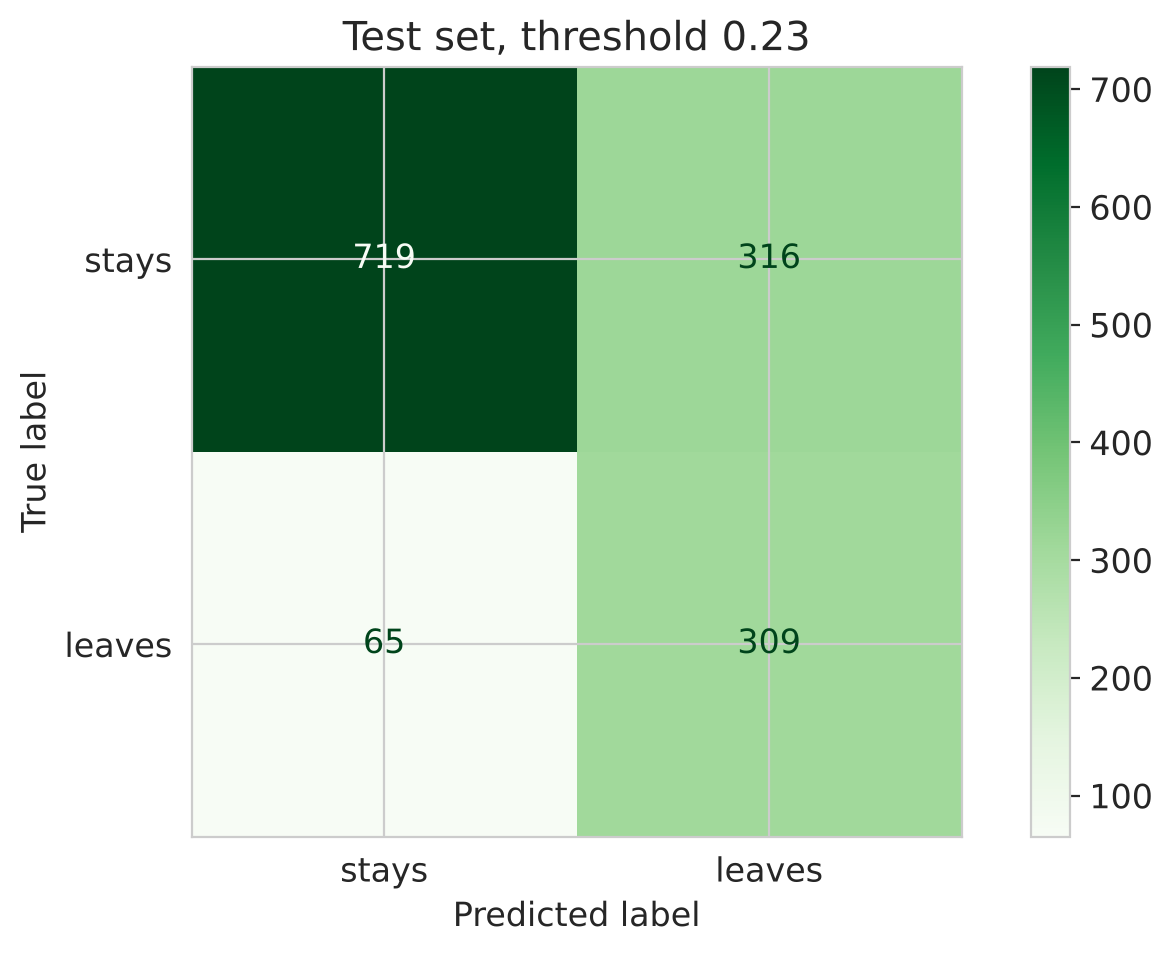

In [16]:
from sklearn.metrics import roc_auc_score, average_precision_score

THRESHOLD = comparison['Gradient boosting']['best threshold']     # decided on training data, NOT on test
final_model = boosting.fit(X_train, y_train)
logreg.fit(X_train, y_train)                                      # fallback, for comparison

p_test = final_model.predict_proba(X_test)[:, 1]
print(f'Test ROC AUC:          {roc_auc_score(y_test, p_test):.4f}   (logistic fallback {roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1]):.4f})')
print(f'Test average precision: {average_precision_score(y_test, p_test):.4f}')
print(f'Threshold {THRESHOLD}: call {np.sum(p_test >= THRESHOLD)} of {len(p_test)} customers')
print(f'Profit on test customers: ${campaign_profit(y_test, p_test, THRESHOLD):,.0f}'
      f'  vs threshold 0.5: ${campaign_profit(y_test, p_test, 0.5):,.0f}'
      f'  vs call everyone: ${campaign_profit(y_test, p_test, 0):,.0f}')

ConfusionMatrixDisplay(confusion_matrix(y_test, p_test >= THRESHOLD), display_labels=['stays', 'leaves']).plot(cmap='Greens', values_format='d')
plt.title(f'Test set, threshold {THRESHOLD}'); plt.show()

The test results match cross-validation: AUC ≈ 0.85, and the profit-based threshold beats both "0.5" and "call everyone" on customers the model has never seen.

Look at the confusion matrix: we now catch most leavers (high recall), at the cost of more wasted calls (lower precision). **That's deliberate:** a miss costs more than a wasted call.

## Step 12 · Why does the model flag customers?

**Permutation importance** (Lesson 5): shuffle one column on the test set and measure how much ROC AUC drops. It works for any model, including boosting.

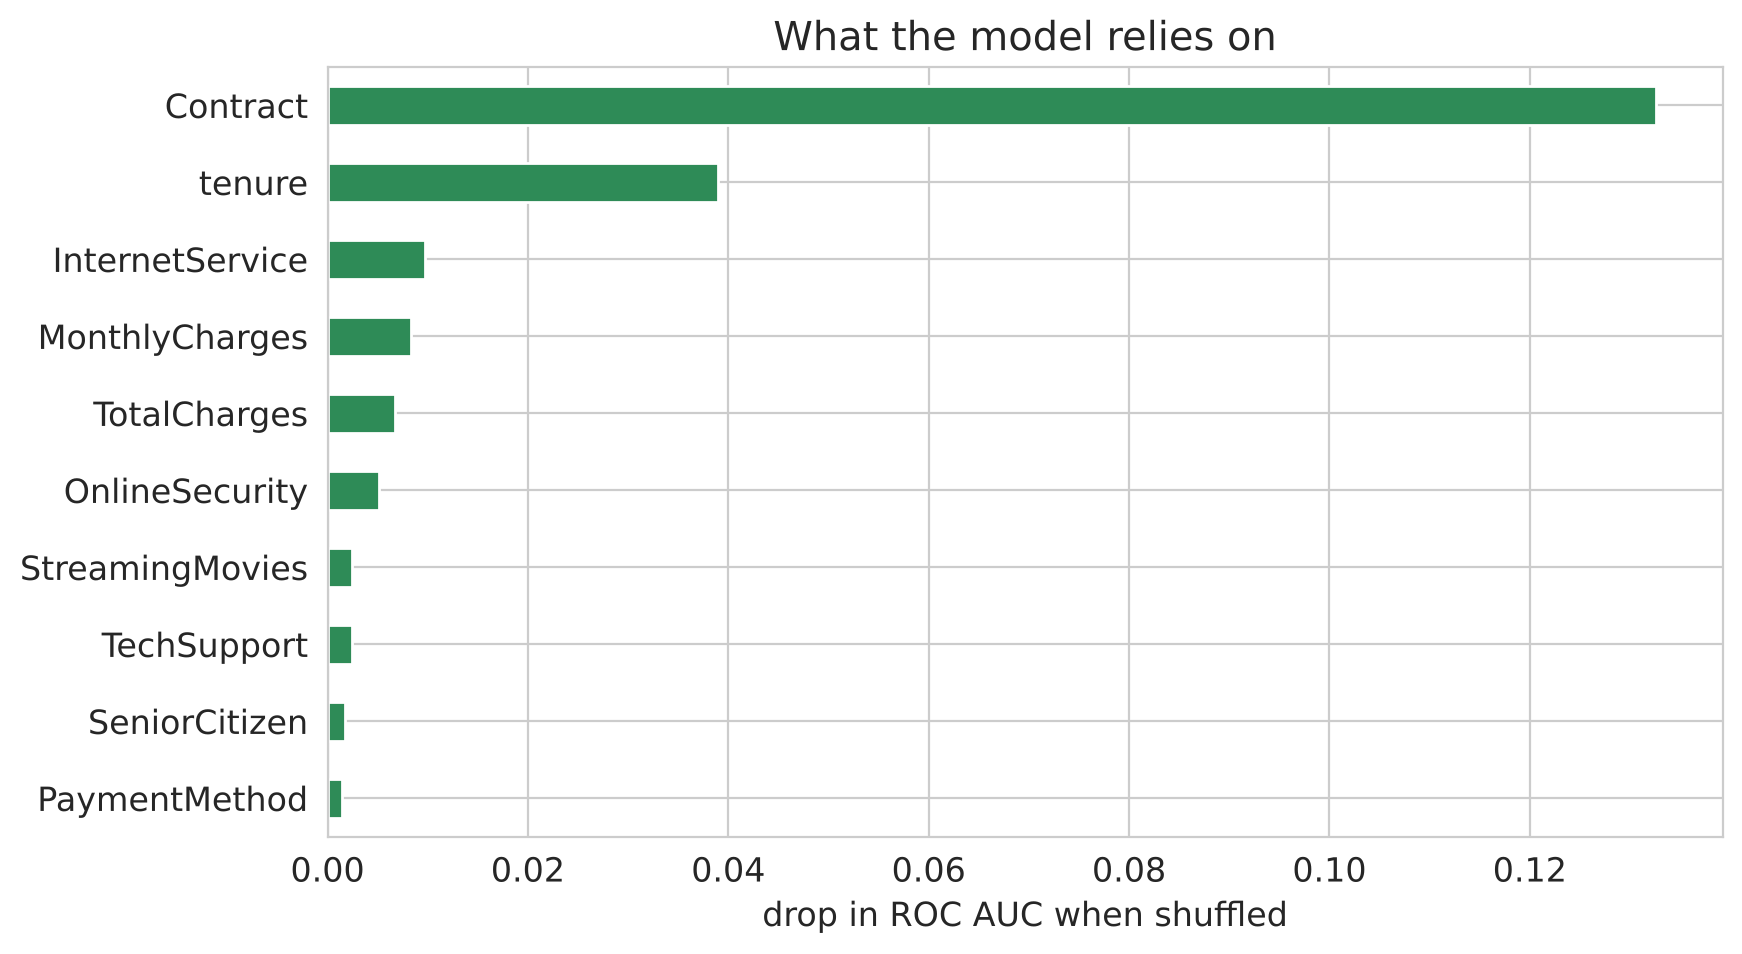

In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=0)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot.barh(color='seagreen'); plt.xlabel('drop in ROC AUC when shuffled'); plt.title('What the model relies on'); plt.show()

For the **direction** of each effect, the logistic fallback is easy to read: positive weight = raises churn risk.

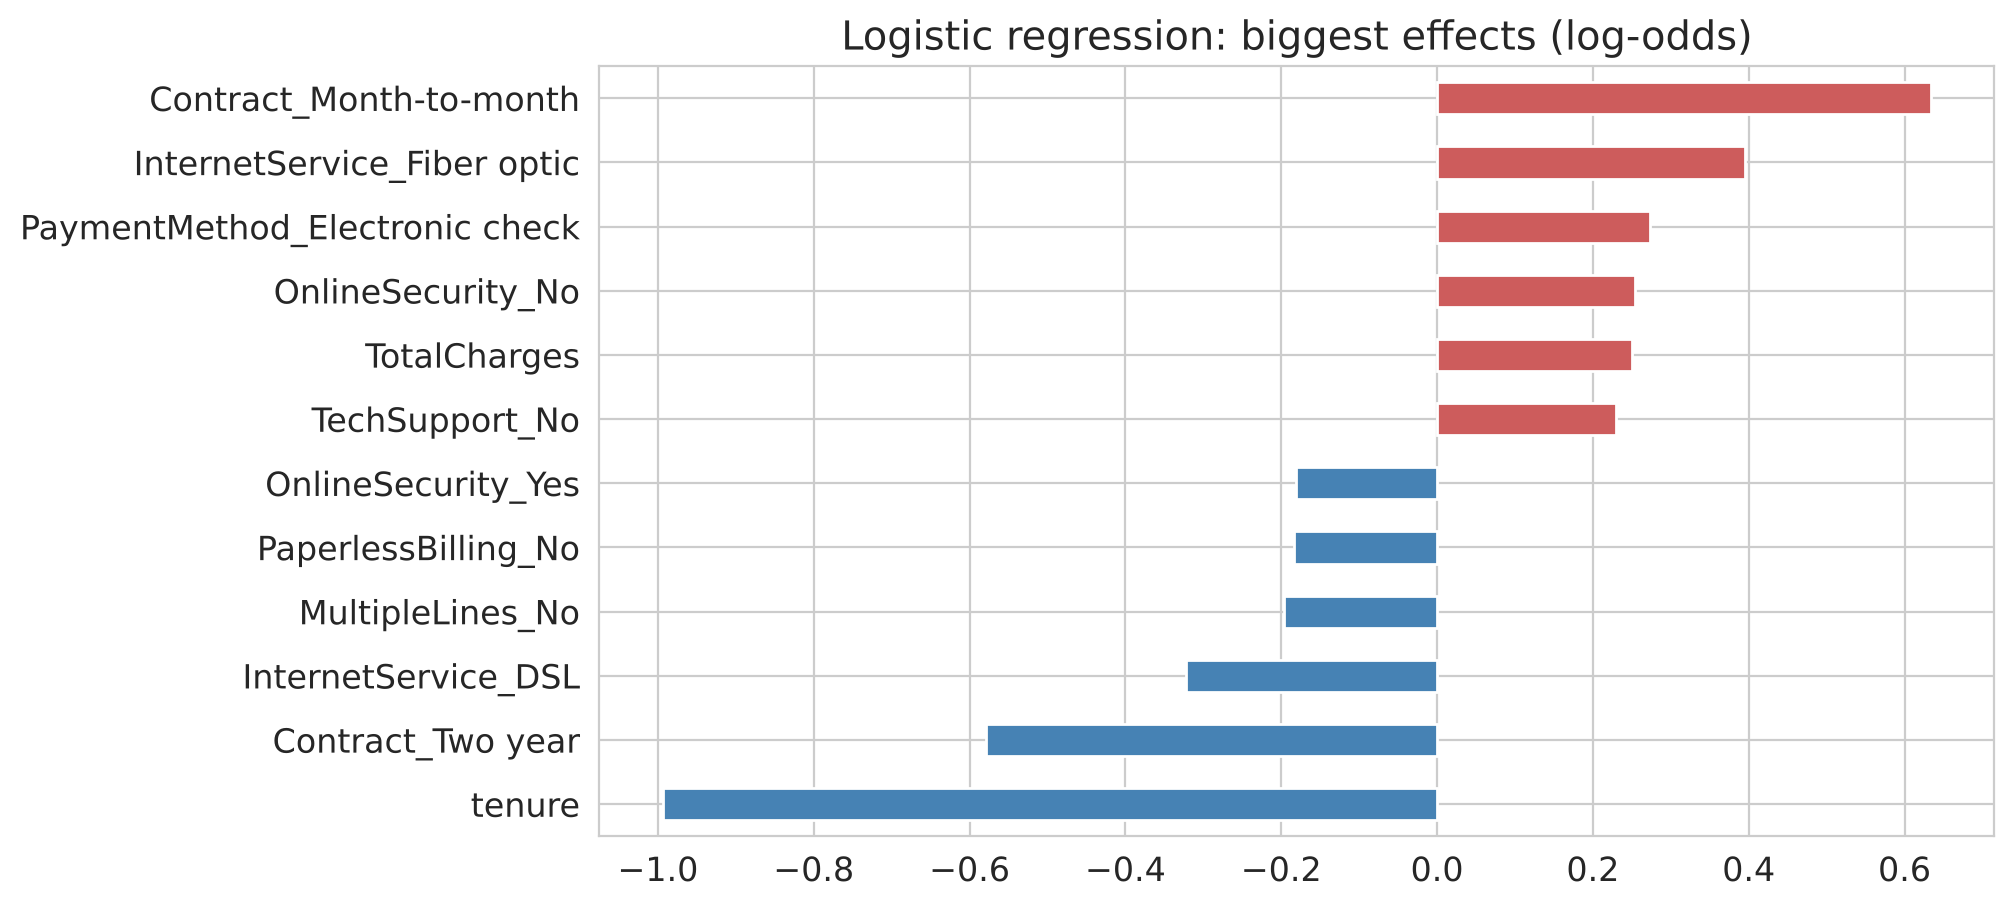

In [18]:
names = [n.split('__')[1] for n in logreg[0].get_feature_names_out()]
coefs = pd.Series(logreg[-1].coef_[0], index=names).sort_values()
pd.concat([coefs.head(6), coefs.tail(6)]).plot.barh(color=['steelblue'] * 6 + ['indianred'] * 6)
plt.title('Logistic regression: biggest effects (log-odds)'); plt.show()

Both models agree on the big picture: **contract type** dominates, then **tenure**, then internet type and charges. Long contracts and long tenure protect; month-to-month and fiber raise risk. The logistic weights add detail: electronic check and having **no** online security or tech support also raise risk. (Permutation importance ranks payment method low because its information overlaps with contract and tenure: shuffling one column hurts little when another column carries the same signal, a known limit from Lesson 5.)

**Remember:** these are associations, not proven causes. "Fiber customers leave more" might mean fiber is overpriced, or that fiber areas have more competitors. Testing a cause needs an experiment (e.g. offer a discount to a random half).

## Step 13 · Segments for the campaign (unsupervised)

The call team asks: *"What do we say to each customer?"* One script for everyone is weak. We use **k-means** (Lesson 7) on simple behaviour features to create segments, each with its own message.

As always: **scale first**, fit on training customers only.

In [19]:
from sklearn.cluster import KMeans

service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
def segment_features(data):
    out = data[['tenure', 'MonthlyCharges']].copy()
    out['n_services'] = (data[service_cols] == 'Yes').sum(axis=1) + (data['InternetService'] != 'No')
    return out

seg_scaler = StandardScaler().fit(segment_features(X_train))
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(seg_scaler.transform(segment_features(X_train)))

profile = segment_features(X_train).assign(segment=kmeans.labels_, churn=y_train.values).groupby('segment').mean()
profile = profile.round({'tenure': 1, 'MonthlyCharges': 1, 'n_services': 1, 'churn': 2})
profile['customers'] = pd.Series(kmeans.labels_).value_counts()
profile

,tenure,MonthlyCharges,n_services,churn,customers
segment,,,,,
0,54.3,30.2,2.1,0.05,766
1,14.8,77.4,4.3,0.47,1901
2,57.4,91.3,6.7,0.16,1755
3,10.4,29.2,1.7,0.23,1212


We give each segment a human name based on its profile (new vs loyal, low vs high bill), then look at the **test** customers we are going to call:

In [20]:
def name_segment(row):
    age = 'New' if row.tenure < 30 else 'Loyal'
    bill = 'high bill' if row.MonthlyCharges > 60 else 'budget'
    return f'{age}, {bill}'

segment_names = profile.apply(name_segment, axis=1).to_dict()
messages = {'New, high bill': 'discount for switching to a 1-year contract',
            'New, budget': 'onboarding help + free add-on trial',
            'Loyal, high bill': 'loyalty reward, check service quality',
            'Loyal, budget': 'thank-you call, light upsell'}

test_segments = kmeans.predict(seg_scaler.transform(segment_features(X_test)))
calls = pd.DataFrame({'segment': [segment_names[s] for s in test_segments], 'prob': p_test, 'left': y_test.values})
calls = calls[calls.prob >= THRESHOLD]
summary = calls.groupby('segment').agg(customers_to_call=('prob', 'size'), avg_risk=('prob', 'mean'), actually_left=('left', 'mean')).round(2)
summary['script'] = summary.index.map(messages)
summary.sort_values('customers_to_call', ascending=False)

,customers_to_call,avg_risk,actually_left,script
segment,,,,
"New, high bill",392,0.54,0.54,discount for switching to a 1-year contract
"New, budget",136,0.43,0.48,onboarding help + free add-on trial
"Loyal, high bill",90,0.40,0.31,"loyalty reward, check service quality"
"Loyal, budget",7,0.35,0.43,"thank-you call, light upsell"


Most calls go to **new, high-bill** customers, so the main script should be a contract-upgrade offer. Clustering didn't make the model more accurate (Lesson 7 showed that), but it makes the **campaign** smarter.

## Step 14 · Production: save, score, call list, monitoring

### 14.1 Save the pipeline (preprocessing + model + threshold)

In [21]:
import joblib, json

joblib.dump(final_model, 'churn_model.joblib')
json.dump({'threshold': float(THRESHOLD), 'cost_per_call': COST_PER_CALL, 'save_rate': SAVE_RATE,
           'customer_value': CUSTOMER_VALUE, 'model': 'HistGradientBoosting v1', 'train_rows': len(X_train)},
          open('churn_model_config.json', 'w'), indent=2)
print(open('churn_model_config.json').read())

{
  "threshold": 0.23,
  "cost_per_call": 100,
  "save_rate": 0.3,
  "customer_value": 1500,
  "model": "HistGradientBoosting v1",
  "train_rows": 5634
}


### 14.2 Score a batch and build tomorrow's call list
Each row gets: probability, expected value of calling, segment, script, and simple **talking points** the caller can read.

In [22]:
model = joblib.load('churn_model.joblib')
config = json.load(open('churn_model_config.json'))

def talking_points(row):
    reasons = []
    if row.Contract == 'Month-to-month': reasons.append('no contract')
    if row.tenure < 12: reasons.append(f'new ({row.tenure} months)')
    if row.InternetService == 'Fiber optic': reasons.append('fiber customer')
    if row.PaymentMethod == 'Electronic check': reasons.append('pays by e-check')
    if row.TechSupport == 'No' and row.InternetService != 'No': reasons.append('no tech support')
    return ', '.join(reasons) or 'general risk'

def build_call_list(customers):
    X = customers[numeric_cols + categorical_cols]
    out = customers[['customerID']].copy()
    out['churn_probability'] = model.predict_proba(X)[:, 1].round(3)
    out['expected_value_of_call'] = (out.churn_probability * config['save_rate'] * config['customer_value'] - config['cost_per_call']).round(0)
    out['segment'] = [segment_names[s] for s in kmeans.predict(seg_scaler.transform(segment_features(X)))]
    out['script'] = out.segment.map(messages)
    out['talking_points'] = customers.apply(talking_points, axis=1)
    out = out[out.churn_probability >= config['threshold']]
    return out.sort_values('expected_value_of_call', ascending=False)

call_list = build_call_list(test_df)        # pretend test_df is tomorrow's customer file
call_list.to_csv('call_list.csv', index=False)
print(f'{len(call_list)} customers to call; expected campaign value ${call_list.expected_value_of_call.sum():,.0f}')
pd.set_option('display.max_colwidth', 70)
call_list[['customerID', 'churn_probability', 'expected_value_of_call', 'segment', 'talking_points']].head(10)

625 customers to call; expected campaign value $77,386


,customerID,churn_probability,expected_value_of_call,segment,talking_points
6866,0295-PPHDO,0.884,298.0,"New, high bill","no contract, new (1 months), fiber customer, pays by e-check, no t..."
3380,5178-LMXOP,0.885,298.0,"New, high bill","no contract, new (1 months), fiber customer, pays by e-check, no t..."
4585,1069-XAIEM,0.881,296.0,"New, high bill","no contract, new (1 months), fiber customer, pays by e-check, no t..."
383,5167-ZFFMM,0.871,292.0,"New, high bill","no contract, new (1 months), fiber customer, no tech support"
6623,9248-OJYKK,0.868,291.0,"New, high bill","no contract, new (1 months), fiber customer, pays by e-check, no t..."
3085,5052-PNLOS,0.864,289.0,"New, high bill","no contract, new (3 months), fiber customer, no tech support"
1073,0655-RBDUG,0.863,288.0,"New, high bill","no contract, new (7 months), fiber customer, no tech support"
2464,2609-IAICY,0.857,286.0,"New, high bill","no contract, new (1 months), fiber customer, pays by e-check, no t..."
2797,6023-YEBUP,0.854,284.0,"New, high bill","no contract, new (3 months), fiber customer, pays by e-check, no t..."
6365,8884-ADFVN,0.851,283.0,"New, high bill","no contract, new (7 months), fiber customer, pays by e-check, no t..."


### 14.3 Monitoring: is tomorrow's data like the training data?
Models silently decay when customers change (new prices, a competitor, a pandemic). This is **drift** (Lesson 2). A standard check is the **Population Stability Index (PSI)** on the score distribution: < 0.1 stable, 0.1–0.25 watch, > 0.25 investigate / retrain.

In [23]:
def psi(expected, actual, bins=10):
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

train_scores = p_boost                      # cross-validated scores on training customers
print(f'PSI, test vs train scores: {psi(train_scores, p_test):.3f}')

# simulate a future month: a marketing push means half the file are brand-new, month-to-month customers
future = test_df.copy()
new = future.sample(frac=0.5, random_state=1).index
future.loc[new, 'tenure'] = 1
future.loc[new, 'TotalCharges'] = future.loc[new, 'MonthlyCharges']
future.loc[new, 'Contract'] = 'Month-to-month'
future_scores = model.predict_proba(future[numeric_cols + categorical_cols])[:, 1]
print(f'PSI after a wave of new customers: {psi(train_scores, future_scores):.3f}  (average risk {p_test.mean():.2f} → {future_scores.mean():.2f})')

PSI, test vs train scores: 0.028
PSI after a wave of new customers: 0.426  (average risk 0.26 → 0.42)


The test month is stable (PSI ≈ 0.03). The simulated wave of new customers pushes PSI far above 0.25: an alarm. The model may still rank well, but the threshold, the call budget and the segment scripts all need a fresh look. In production this check runs automatically every week and alerts the team.

**Full production loop:** data checks → score → call list → campaign → record outcomes → monitor drift and real profit → retrain on new outcomes.

## Step 15 · Summary: the whole course in one lab

| What we did | Concept | Lesson |
|---|---|---|
| Framed the problem in dollars | supervised classification, business metric | 1, 3 |
| Investigated blank TotalCharges → filled with 0 | missing data has a reason | 1 |
| Kept look-alike rows (different IDs), dropped ID column | duplicates vs leakage | 2 |
| Stratified split, CV, test used once | honest evaluation | 2 |
| "Nobody leaves" = 73.5% accuracy | accuracy trap, baselines | 3 |
| Logistic regression in a pipeline | sigmoid, log loss, scaling, encoding | 4 |
| Confusion matrix, precision, recall, ROC, PR | classification metrics | 3 |
| Threshold ≈ 0.22 by profit (and by formula) | cost-based decisions | 3 |
| Balanced weights broke calibration | calibration | 3 |
| Tuned tree, forest, boosting; defaults trap | trees and ensembles | 5, 6 |
| Permutation importance + coefficients | explaining models | 4, 5 |
| k-means segments → scripts | unsupervised learning | 7 |
| Saved pipeline + config, call list, PSI drift check | production | — |

### Exercises
1. Change the business numbers (call cost \$50, save rate 20%). Predict the new best threshold with the formula, then check with the profit curve.
2. Add a feature `n_services` to the model. Does cross-validated AUC or profit change? Why or why not?
3. Calibrate the `class_weight='balanced'` model with `CalibratedClassifierCV` and re-plot calibration.
4. Try `XGBClassifier` (pre-installed in Colab) with the same pipeline. Is it worth the extra dependency?
5. The team can only make **300 calls**. How would you change the call list? What profit do you expect?

*Data: IBM Telco Customer Churn sample dataset. Business numbers are illustrative assumptions. Book background (optional): Géron, Hands-On Machine Learning, Ch 3, 6, 7, 8.*